# Crop Yield Prediction using Machine Learning
### Linear Regression vs Decision Tree vs Random Forest

In this project we predict **crop yield (kg/ha)** from weather, pesticide use, crop type, country and year,
and compare three regression algorithms:

1. **Linear Regression**
2. **Decision Tree Regression**
3. **Random Forest Regression**

All three models use the **same features** and the **same train/test split**, so the comparison at the end is fair.

## Step 0: Import Libraries
All the Python tools used in this notebook are imported once here:
- **pandas / numpy** → to read and work with the data
- **matplotlib / seaborn** → to make graphs
- **scikit-learn** → for preprocessing, the three models and the evaluation metrics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
print("Libraries loaded successfully!")

Libraries loaded successfully!


## Step 1: Load the Data
**Before running this cell:**
1. Download the dataset from Kaggle (search: *"crop yield prediction dataset"*)
2. Extract the zip file and find **`yield_df.csv`**
3. Upload `yield_df.csv` to Colab (Files panel on the left) so the path is `/content/yield_df.csv`

In [2]:
df = pd.read_csv("/content/yield_df.csv")
print("Data loaded!")
df.head()

Data loaded!


,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [3]:
# Size of the data
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows   : 28242
Number of columns: 8


In [4]:
# Column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  object 
 2   Item                           28242 non-null  object 
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), object(2)
memory usage: 1.7+ MB


### What the columns mean
| Column | Meaning |
|---|---|
| Area | Country name |
| Item | Crop name (Rice, Wheat, Maize, etc.) |
| Year | Year of the record |
| hg/ha_yield | Crop yield in hectograms per hectare |
| average_rain_fall_mm_per_year | Yearly rainfall (mm) |
| pesticides_tonnes | Pesticides used (tonnes) |
| avg_temp | Average temperature (°C) |

## Step 2: Clean the Data
We will:
1. Remove the extra index column (`Unnamed: 0`)
2. Give the columns short, simple names
3. Convert yield from hg/ha to **kg/ha** (easier to understand; 1 hg = 0.1 kg)
4. Remove missing values and duplicate rows

In [5]:
# 1. Remove the extra index column if it exists
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# 2. Rename columns
df = df.rename(columns={
    "Area": "Country",
    "Item": "Crop",
    "hg/ha_yield": "Yield",
    "average_rain_fall_mm_per_year": "Rainfall",
    "pesticides_tonnes": "Pesticides",
    "avg_temp": "Temperature"
})

# 3. Convert yield to kg per hectare
df["Yield"] = df["Yield"] / 10

# 4. Remove missing values and duplicates
print("Missing values before cleaning:")
print(df.isnull().sum())
before = len(df)
df = df.dropna().drop_duplicates().reset_index(drop=True)
print("\nRows removed:", before - len(df))
print("Rows remaining:", len(df))

df.head()

Missing values before cleaning:
Country        0
Crop           0
Year           0
Yield          0
Rainfall       0
Pesticides     0
Temperature    0
dtype: int64

Rows removed: 2310
Rows remaining: 25932


,Country,Crop,Year,Yield,Rainfall,Pesticides,Temperature
0,Albania,Maize,1990,3661.3,1485.0,121.0,16.37
1,Albania,Potatoes,1990,6666.7,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,2333.3,1485.0,121.0,16.37
3,Albania,Sorghum,1990,1250.0,1485.0,121.0,16.37
4,Albania,Soybeans,1990,700.0,1485.0,121.0,16.37


In [6]:
# Basic statistics (mean, min, max, etc.)
df.describe().round(2)

,Year,Yield,Rainfall,Pesticides,Temperature
count,25932.00,25932.00,25932.00,25932.00,25932.00
mean,2001.56,7697.81,1146.84,34782.57,20.42
std,7.06,8464.76,717.39,57228.57,6.44
min,1990.00,5.00,51.00,0.04,1.30
25%,1995.00,1999.60,593.00,1597.00,16.58
50%,2001.00,3953.00,1083.00,15373.00,21.42
75%,2008.00,10416.80,1668.00,45620.00,26.06
max,2013.00,50141.20,3240.00,367778.00,30.65


In [7]:
# Which crops are in the data?
print("Crops in dataset:")
print(df["Crop"].value_counts())

Crops in dataset:
Crop
Potatoes                3956
Maize                   3824
Wheat                   3539
Rice, paddy             3091
Soybeans                2940
Sorghum                 2770
Sweet potatoes          2593
Cassava                 1889
Yams                     774
Plantains and others     556
Name: count, dtype: int64


## Step 3: Graphs (Exploratory Data Analysis)
After each graph, write what you observe in the **Observation** box.

### Graph 1: Average Yield Over the Years

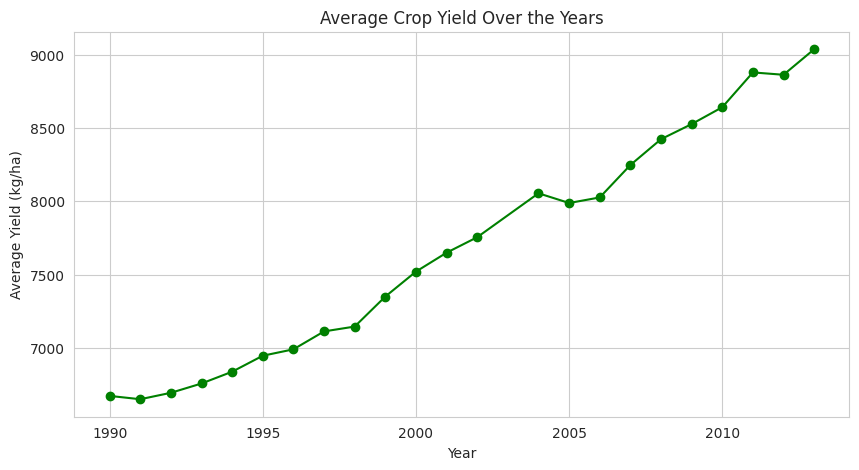

In [8]:
yearly = df.groupby("Year")["Yield"].mean()

plt.plot(yearly.index, yearly.values, marker="o", color="green")
plt.title("Average Crop Yield Over the Years")
plt.xlabel("Year")
plt.ylabel("Average Yield (kg/ha)")
plt.show()

**Observation:**

### Graph 2: Average Yield of Each Crop

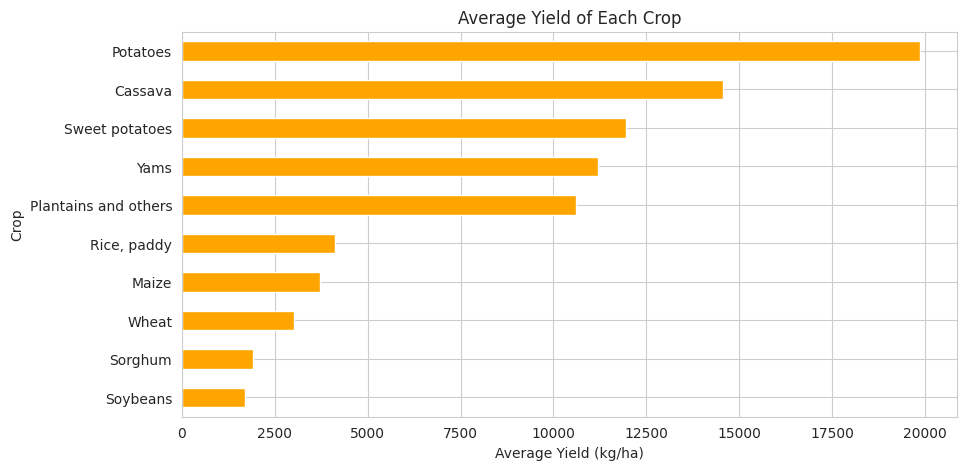

In [9]:
crop_yield = df.groupby("Crop")["Yield"].mean().sort_values()

crop_yield.plot(kind="barh", color="orange")
plt.title("Average Yield of Each Crop")
plt.xlabel("Average Yield (kg/ha)")
plt.ylabel("Crop")
plt.show()

**Observation:**

### Graph 3: Rainfall vs Yield

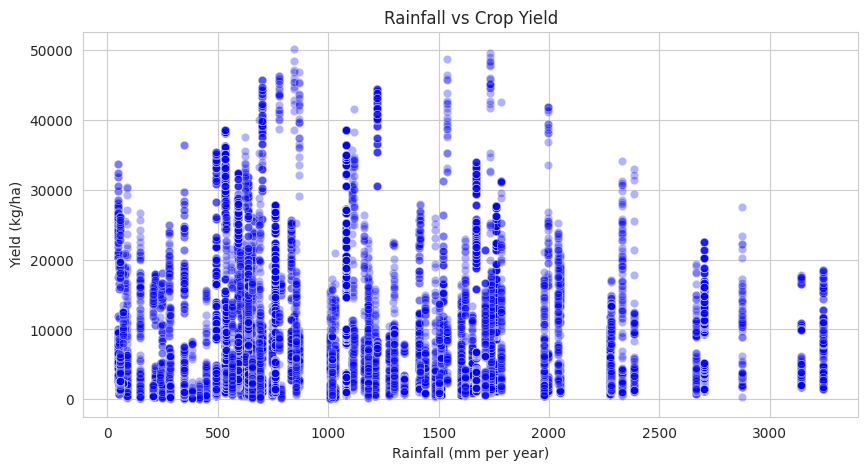

In [10]:
sns.scatterplot(data=df, x="Rainfall", y="Yield", alpha=0.3, color="blue")
plt.title("Rainfall vs Crop Yield")
plt.xlabel("Rainfall (mm per year)")
plt.ylabel("Yield (kg/ha)")
plt.show()

**Observation:**

### Graph 4: Temperature vs Yield

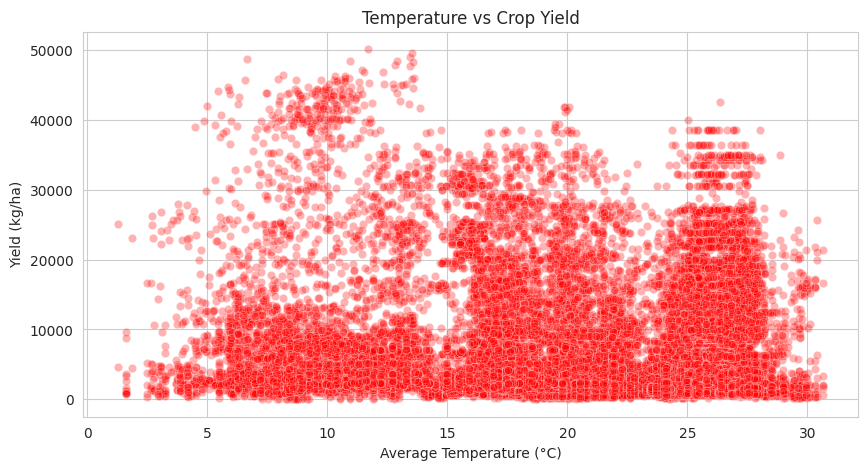

In [11]:
sns.scatterplot(data=df, x="Temperature", y="Yield", alpha=0.3, color="red")
plt.title("Temperature vs Crop Yield")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Yield (kg/ha)")
plt.show()

**Observation:**

### Graph 5: Rainfall vs Yield for One Crop (Rice)
Different crops behave differently, so let's look at just one crop. You can change `"Rice, paddy"` to any crop name from the list above.

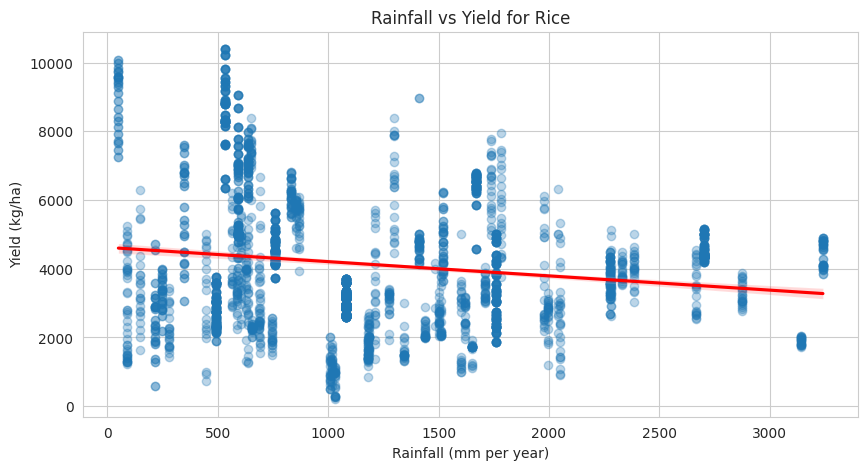

In [12]:
one_crop = df[df["Crop"] == "Rice, paddy"]

sns.regplot(data=one_crop, x="Rainfall", y="Yield",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Rainfall vs Yield for Rice")
plt.xlabel("Rainfall (mm per year)")
plt.ylabel("Yield (kg/ha)")
plt.show()

**Observation:**

### Graph 6: Correlation Heatmap
Correlation shows how strongly two things are related:
- Close to **+1** → both increase together
- Close to **−1** → one increases, the other decreases
- Close to **0** → no clear relation

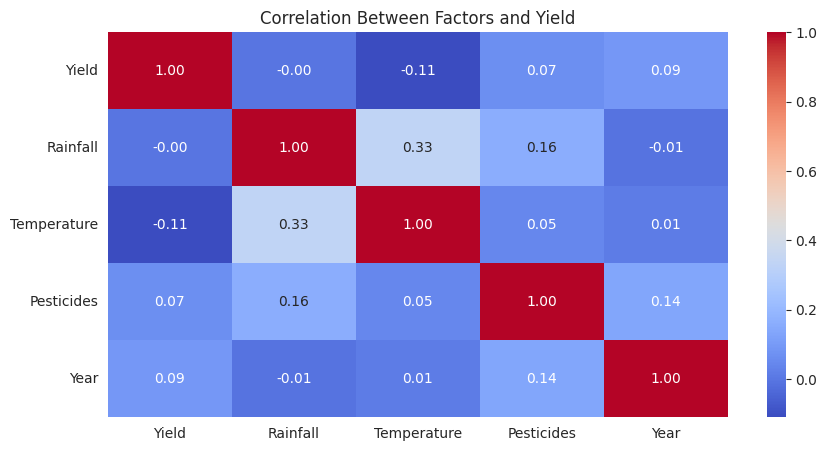

In [13]:
corr = df[["Yield", "Rainfall", "Temperature", "Pesticides", "Year"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Factors and Yield")
plt.show()

**Observation:**

## Step 4: Prepare the Data for All Three Models
This step is done **once** and shared by all three algorithms.

- **Inputs (X):** Rainfall, Temperature, Pesticides, Crop, Country, Year
- **Output (y):** Yield

`Crop` and `Country` are text, so **One-Hot Encoding** turns them into 0/1 columns. The numeric columns are passed through unchanged.
We use **80%** of the data to **train** and **20%** to **test**. Because every model uses this same split, the comparison is fair.

In [14]:
categorical_features = ["Crop", "Country"]
numeric_features     = ["Rainfall", "Temperature", "Pesticides", "Year"]
features = numeric_features + categorical_features

X = df[features]
y = df["Yield"]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numeric", "passthrough", numeric_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

Training samples: 20745
Testing samples : 5187


### Helper functions
These two small functions are used by every model, so we don't repeat the same code three times.
- `evaluate()` prints **MAE**, **RMSE** and **R²** and returns them
- `plot_actual_vs_predicted()` draws the actual-vs-predicted scatter plot

**How to read the metrics:**
- **MAE (Mean Absolute Error)** → on average, how far the prediction is from the real value (lower is better)
- **RMSE (Root Mean Squared Error)** → like MAE but punishes big mistakes more (lower is better)
- **R² Score** → between 0 and 1; closer to 1 means the model explains the yield better

In [15]:
def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"{name} Results")
    print("-" * (len(name) + 8))
    print(f"MAE  : {mae:.2f} kg/ha")
    print(f"RMSE : {rmse:.2f} kg/ha")
    print(f"R²   : {r2:.4f}")
    return {"Algorithm": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2}


def plot_actual_vs_predicted(name, y_true, y_pred, color, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(y_true, y_pred, alpha=0.4, color=color)
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    ax.plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual Yield (kg/ha)")
    ax.set_ylabel("Predicted Yield (kg/ha)")
    ax.legend()
    return ax


results = []   # the result of each model will be stored here

## Step 5: Algorithm 1 — Linear Regression
**Linear Regression** draws the best straight-line relationship between the inputs and the output.

### 5a. Why the features matter (weather only)
First, a quick test with **only Rainfall and Temperature**. The R² score will be very low, because yield depends a lot on
**which crop** it is (potatoes give far more kg/ha than wheat) — weather alone can't explain that.

In [16]:
lr_weather = LinearRegression()
lr_weather.fit(X_train[["Rainfall", "Temperature"]], y_train)
pred_weather = lr_weather.predict(X_test[["Rainfall", "Temperature"]])

print("Linear Regression (Weather only)")
print("R² Score :", round(r2_score(y_test, pred_weather), 3))
print("MAE      :", round(mean_absolute_error(y_test, pred_weather), 2), "kg/ha")

Linear Regression (Weather only)
R² Score : 0.013
MAE      : 6420.65 kg/ha


### 5b. Linear Regression with all features
Now we train Linear Regression on the **same features as the other two models**.

In [17]:
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

results.append(evaluate("Linear Regression", y_test, lr_predictions))

Linear Regression Results
-------------------------
MAE  : 3283.47 kg/ha
RMSE : 5223.95 kg/ha
R²   : 0.6235


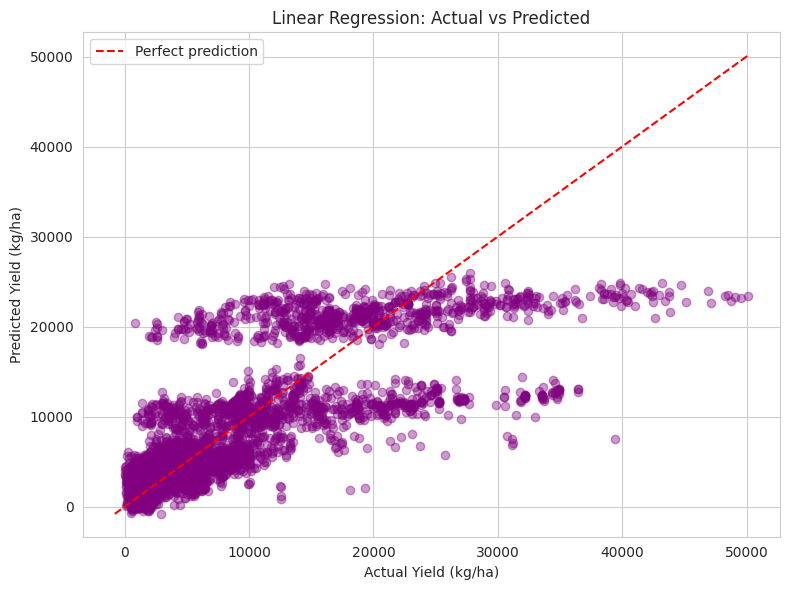

In [18]:
plot_actual_vs_predicted("Linear Regression", y_test, lr_predictions, "purple")
plt.tight_layout()
plt.show()

**Observation:**

## Step 6: Algorithm 2 — Decision Tree Regression
A **Decision Tree** learns a series of yes/no rules (for example *"Is the crop Potatoes?"*, *"Is rainfall > 1000 mm?"*)
and splits the data into smaller and smaller groups. The prediction is the average yield of the group a row ends up in.

`max_depth`, `min_samples_split` and `min_samples_leaf` limit how big the tree can grow, which helps reduce **overfitting**.

In [19]:
dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", DecisionTreeRegressor(
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ))
])

dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)

results.append(evaluate("Decision Tree", y_test, dt_predictions))

Decision Tree Results
---------------------
MAE  : 755.38 kg/ha
RMSE : 1601.74 kg/ha
R²   : 0.9646


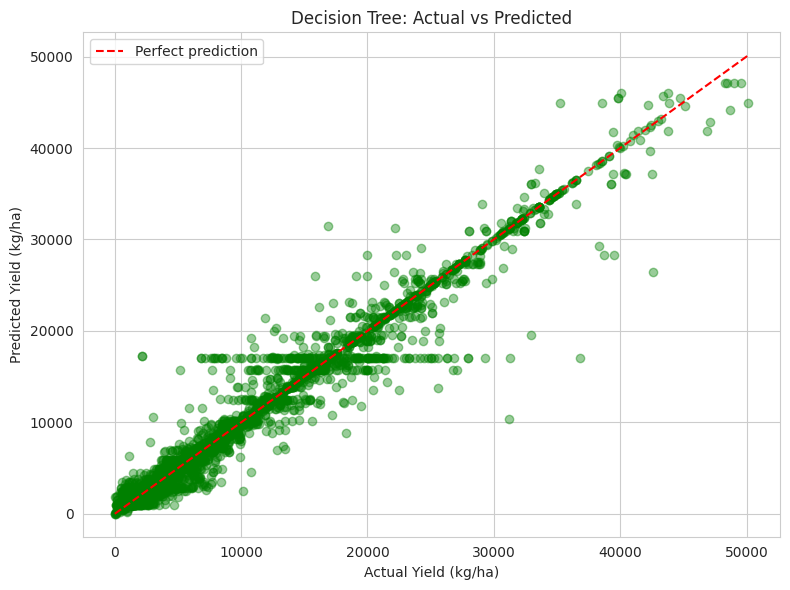

In [20]:
plot_actual_vs_predicted("Decision Tree", y_test, dt_predictions, "green")
plt.tight_layout()
plt.show()

**Observation:**

## Step 7: Algorithm 3 — Random Forest Regression
A **Random Forest** builds many decision trees (here **300**), each on a random sample of the data,
and averages their predictions. Averaging many trees usually gives more accurate and more stable results than a single tree.

In [21]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

results.append(evaluate("Random Forest", y_test, rf_predictions))

Random Forest Results
---------------------
MAE  : 403.12 kg/ha
RMSE : 1066.91 kg/ha
R²   : 0.9843


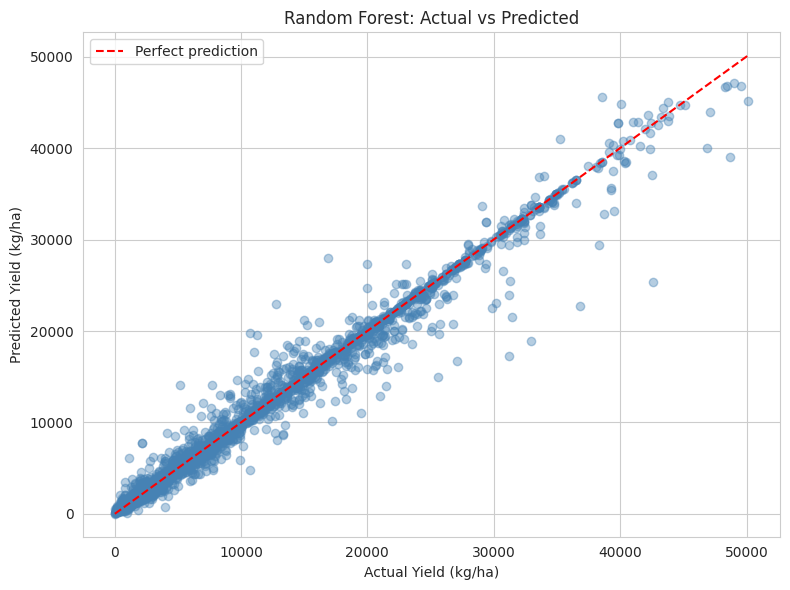

In [22]:
plot_actual_vs_predicted("Random Forest", y_test, rf_predictions, "steelblue")
plt.tight_layout()
plt.show()

**Observation:**

### Which features matter most? (Random Forest)
Random Forest can tell us how much each feature helped in making predictions.
The Crop and Country columns were split into many 0/1 columns, so we add them back together to get one importance value per original feature.

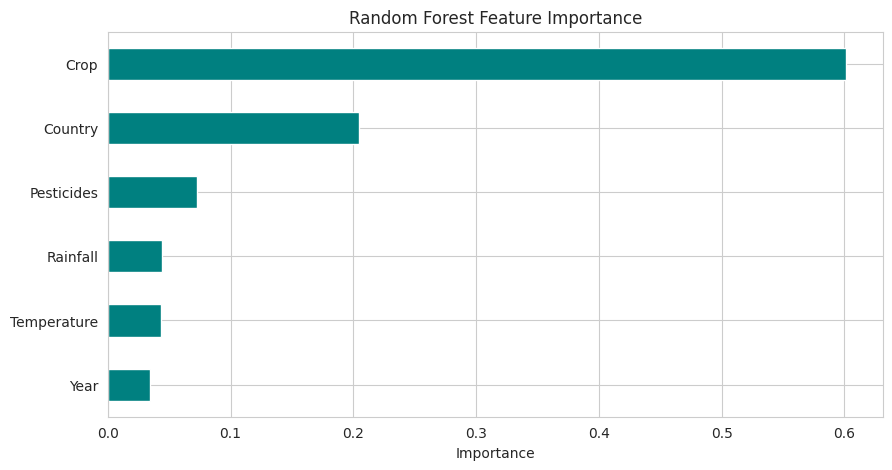

Crop           60.13 %
Country        20.48 %
Pesticides      7.23 %
Rainfall        4.43 %
Temperature     4.31 %
Year            3.42 %
dtype: object


In [23]:
encoded_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
importances   = rf_model.named_steps["regressor"].feature_importances_

imp = pd.Series(importances, index=encoded_names)

# Group the one-hot columns back into their original feature
def original_feature(col):
    col = col.split("__", 1)[1]           # remove the "categorical__" / "numeric__" prefix
    for f in categorical_features:
        if col.startswith(f + "_"):
            return f
    return col

imp_grouped = imp.groupby(original_feature).sum().sort_values()

imp_grouped.plot(kind="barh", color="teal")
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

print((imp_grouped.sort_values(ascending=False) * 100).round(2).astype(str) + " %")

**Observation:**

## Step 8: Comparison of the Three Algorithms
All three models were trained and tested on exactly the same data, so their scores can be compared directly.
The best model has the **lowest MAE and RMSE** and the **highest R²**.

In [24]:
comparison = pd.DataFrame(results)

print("Model Performance Comparison")
print("============================")
print(comparison.round(4).to_string(index=False))

best_model = comparison.loc[comparison["MAE"].idxmin(), "Algorithm"]
print(f"\nBest model (lowest MAE): {best_model}")

Model Performance Comparison
        Algorithm       MAE      RMSE  R2 Score
Linear Regression 3283.4691 5223.9549    0.6235
    Decision Tree  755.3827 1601.7390    0.9646
    Random Forest  403.1183 1066.9078    0.9843

Best model (lowest MAE): Random Forest


### Comparison graphs
MAE/RMSE are in kg/ha (thousands) while R² is between 0 and 1, so they are drawn on **separate graphs** — otherwise the R² bars would be too small to see.

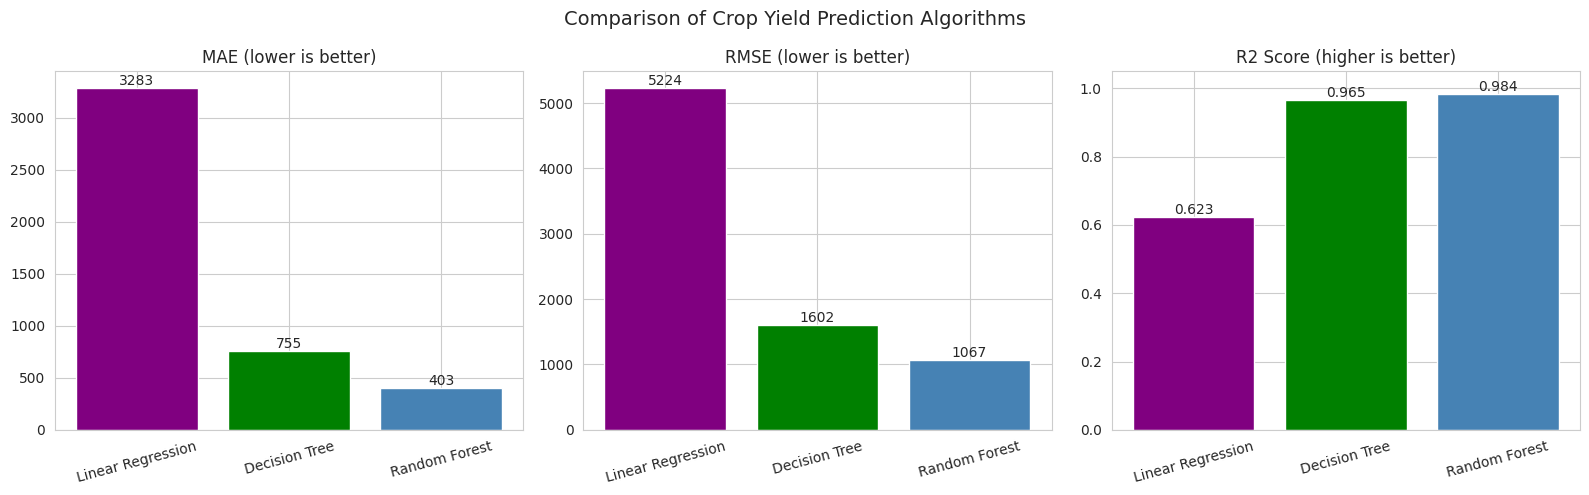

In [25]:
colors = ["purple", "green", "steelblue"]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ["MAE", "RMSE", "R2 Score"]):
    bars = ax.bar(comparison["Algorithm"], comparison[metric], color=colors)
    ax.set_title(metric + (" (lower is better)" if metric != "R2 Score" else " (higher is better)"))
    ax.tick_params(axis="x", rotation=15)
    for bar, val in zip(bars, comparison[metric]):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                f"{val:.3f}" if metric == "R2 Score" else f"{val:.0f}",
                ha="center", va="bottom")

axes[2].set_ylim(0, 1.05)
plt.suptitle("Comparison of Crop Yield Prediction Algorithms", fontsize=14)
plt.tight_layout()
plt.show()

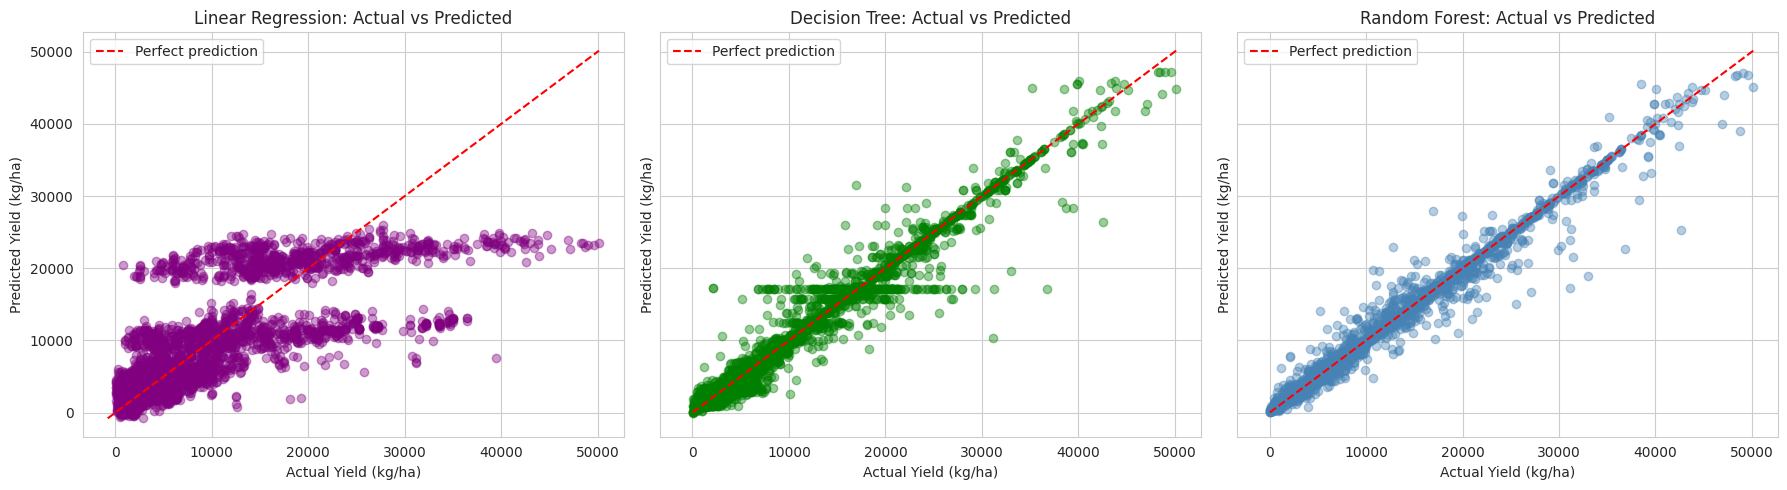

In [26]:
# Actual vs Predicted for all three models side by side
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

all_predictions = [lr_predictions, dt_predictions, rf_predictions]
for ax, name, pred, color in zip(axes, comparison["Algorithm"], all_predictions, colors):
    plot_actual_vs_predicted(name, y_test, pred, color, ax=ax)

plt.tight_layout()
plt.show()

In [27]:
# Actual vs predicted values of all three models for the first 10 test rows
side_by_side = pd.DataFrame({
    "Crop": X_test["Crop"].values,
    "Country": X_test["Country"].values,
    "Actual Yield": y_test.values,
    "Linear Regression": lr_predictions,
    "Decision Tree": dt_predictions,
    "Random Forest": rf_predictions
}).round(1)

side_by_side.head(10)

,Crop,Country,Actual Yield,Linear Regression,Decision Tree,Random Forest
0,Cassava,Angola,15578.2,11083.6,10207.2,12925.0
1,Soybeans,Thailand,1578.7,1532.8,967.0,1568.5
2,Maize,Turkey,7261.4,5228.5,6846.9,7438.7
3,Sorghum,South Africa,3077.4,3160.9,1198.2,1964.4
4,Wheat,Canada,2808.5,5113.3,3309.4,2837.9
5,Maize,Dominican Republic,1335.0,2159.3,2818.8,1371.8
6,Potatoes,Croatia,15399.7,22809.7,17068.4,16166.6
7,"Rice, paddy",Dominican Republic,4809.2,2048.1,5168.1,8497.4
8,Cassava,Ecuador,2511.2,11342.9,3865.0,3458.8
9,Potatoes,Guatemala,36796.9,20973.9,17068.4,22720.8


**Observation:**

## Step 9: Try Your Own Prediction
Change the values below and run the cell. All three models will predict the yield for the same input.
Use a crop and country name exactly as they appear in the dataset.

In [28]:
new_data = pd.DataFrame([{
    "Rainfall":    1200,           # mm per year
    "Temperature": 26,             # °C
    "Pesticides":  15000,          # tonnes
    "Year":        2013,
    "Crop":        "Rice, paddy",  # pick a crop from the list above
    "Country":     "India"
}])

print("Input:")
print(new_data.to_string(index=False))
print("\nPredicted Yield:")
for name, model in [("Linear Regression", lr_model),
                    ("Decision Tree", dt_model),
                    ("Random Forest", rf_model)]:
    print(f"  {name:<18}: {model.predict(new_data)[0]:.2f} kg/ha")

Input:
 Rainfall  Temperature  Pesticides  Year        Crop Country
     1200           26       15000  2013 Rice, paddy   India

Predicted Yield:
  Linear Regression : 5664.44 kg/ha
  Decision Tree     : 3445.46 kg/ha
  Random Forest     : 3928.47 kg/ha


## Conclusion
This project predicted crop yield using three machine learning algorithms — **Linear Regression**, **Decision Tree Regression**
and **Random Forest Regression** — all trained on the same features (rainfall, temperature, pesticide use, crop type, country and year)
and tested on the same 20% of the data.

- **Linear Regression** is simple and easy to interpret, but it can only learn straight-line relationships, so it has the highest error.
  The weather-only test also showed that weather alone explains very little of the yield — crop type and location matter most.
- **Decision Tree** captures non-linear patterns and interactions (e.g. a crop behaving differently in different countries), so it is far more accurate than Linear Regression.
- **Random Forest** averages 300 trees, which reduces the errors of a single tree. It gave the **lowest MAE and RMSE and the highest R²**, making it the best model for this dataset.

The feature-importance graph shows which factors influence the predictions the most. Overall, the project shows that
weather, pesticide use, crop type, location and year together can be used to predict crop yield with good accuracy.